# MetricSuite 2 -- Data plots: look before you test

`suite.plot` has two families of figures:

| family | methods | takes | shows |
|---|---|---|---|
| **data plots** | `box`, `violin`, `bar`, `point`, `strip`, `line`, `scatter`, `distribution`, `histogram` | a metric name | the data, no test |
| **stat plots** | `group_comparison`, `paired_differences`, `estimate`, `anova`, `normality_test`, `cluster_permutation` | a result | what that result tested |

This tutorial is about the first family: checking the shape of the data, and drawing
means or medians with their intervals, before (or without) running any test. The
stat plots come with the tests, in tutorials 3 to 7.

- **Part 1** -- the five categorical views;
- **Part 2** -- what the plot summarizes: `center` and `interval`;
- **Part 3** -- variables: `x`, `hue`, and the all-important `unit`;
- **Part 4** -- distributions, curves and scatter plots;
- **Part 5** -- styling and multi-panel figures.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from mindmap.metric import MetricSuite

COLORS = {"wCSET": "#2a78d6", "CSET": "#1baf7a", "dSPM": "#e34948"}
ORDER = ["wCSET", "CSET", "dSPM"]

### The fake study

Three methods localize simulated spikes in 16 patients, at two noise levels
(`snr` = `"low"` / `"high"`), with 4 simulation runs per condition. The
localization error is right-skewed (lognormal), and one patient is much harder than
the others -- the kind of data where a mean and a median tell different stories.

Each patient also has a source depth (`depth_mm`), and every run produces a
correlation curve over time (`correlation_t`).

In [2]:
TRUE_ERROR = {"wCSET": 12.0, "CSET": 14.0, "dSPM": 20.0}   # median error, mm
SNR_FACTOR = {"high": 1.0, "low": 1.5}
N_PATIENTS, N_RUNS = 16, 4
TIMES = np.linspace(-0.05, 0.15, 41)

rng = np.random.default_rng(0)
suite = MetricSuite(name="Data plots")
for p in range(N_PATIENTS):
    patient = f"P{p:02d}"
    depth = rng.uniform(10, 50)
    hardness = 2.5 if p == 0 else np.exp(rng.normal(0, 0.25))   # P00 is an outlier
    for method, mu in TRUE_ERROR.items():
        for snr, factor in SNR_FACTOR.items():
            for run in range(N_RUNS):
                err = mu * factor * hardness * (1 + depth / 100) * np.exp(rng.normal(0, 0.25))
                suite.register("loc_error_mm", err, method=method, snr=snr, patient=patient,
                               run=run, depth_mm=depth)
        peak = 0.9 - TRUE_ERROR[method] / 60
        curve = peak * np.exp(-((TIMES - 0.03) / 0.04) ** 2) + rng.normal(0, 0.06, size=(N_RUNS, TIMES.size))
        suite.register("correlation_t", curve, method=method, patient=patient, times=TIMES)

suite.describe()

,Metric,Coord,Kind,N unique,Detail
0,correlation_t,method,categorical,3,"CSET, dSPM, wCSET"
1,correlation_t,patient,categorical,16,"P00, P01, P02, P03, P04, P05, P06, P07, ... (+..."
2,correlation_t,rep,numerical,4,"[0, 3]"
3,correlation_t,times,numerical,41,"[-0.05, 0.15]"
4,loc_error_mm,method,categorical,3,"CSET, dSPM, wCSET"
5,loc_error_mm,snr,categorical,2,"high, low"
6,loc_error_mm,patient,categorical,16,"P00, P01, P02, P03, P04, P05, P06, P07, ... (+..."
7,loc_error_mm,run,numerical,4,"[0, 3]"
8,loc_error_mm,depth_mm,numerical,16,"[11.4566, 43.9821]"


## 📦 - Part 1: Five ways to show groups

`box`, `violin`, `bar`, `point` and `strip` all take the same arguments:
`metric`, then `x` (the groups on the axis), then optional `hue` (a second grouping)
and `unit` (explained in Part 3). Each one has a sensible default summary:

| view | default | good for |
|---|---|---|
| `box` | median, quartiles, whiskers, points | robust overview of a skewed sample |
| `violin` | density + median and IQR | the shape of a large sample |
| `bar` | mean and 95% CI | means of bounded data (e.g. proportions) |
| `point` | mean and 95% CI | comparing centers across many groups |
| `strip` | every point + mean and 95% CI | small samples: show everything |

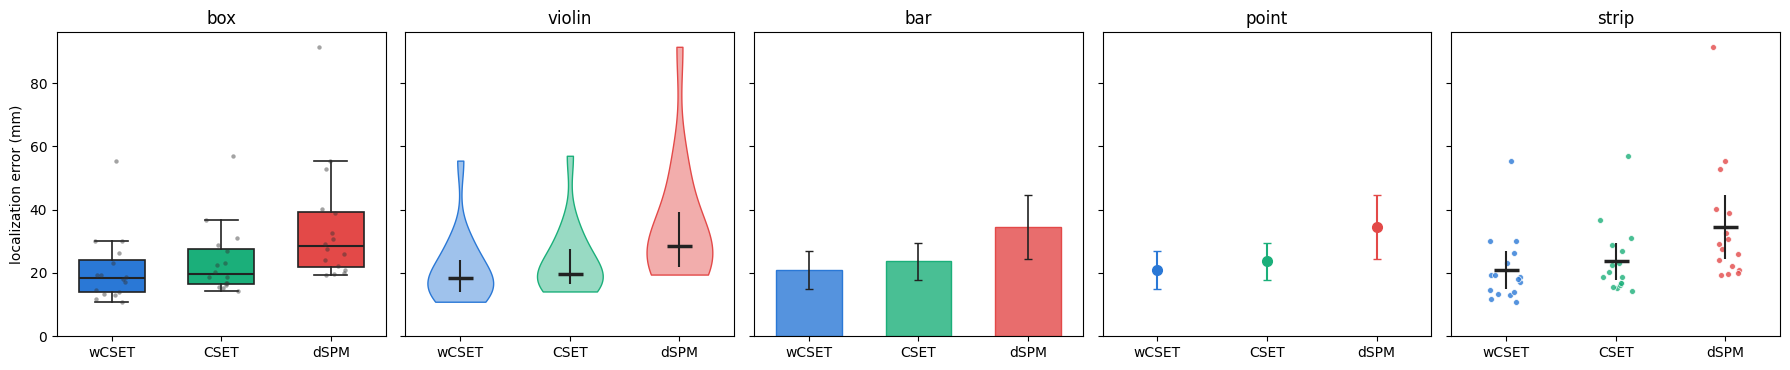

In [3]:
fig, axes = plt.subplots(1, 5, figsize=(18, 3.8), sharey=True)
kws = dict(x="method", unit="patient", order=ORDER, palette=COLORS, xlabel="", ylabel="")
suite.plot.box("loc_error_mm", ax=axes[0], title="box", **kws)
suite.plot.violin("loc_error_mm", ax=axes[1], title="violin", **kws)
suite.plot.bar("loc_error_mm", ax=axes[2], title="bar", **kws)
suite.plot.point("loc_error_mm", ax=axes[3], title="point", **kws)
suite.plot.strip("loc_error_mm", ax=axes[4], title="strip", **kws)
axes[0].set_ylabel("localization error (mm)")
fig.tight_layout()

## 🎯 - Part 2: What the plot summarizes

Two arguments choose the summary drawn on every categorical view:

- `center`: `"mean"`, `"median"` (or `"proportion"` for 0/1 data, tutorial 5);
- `interval`: `"iqr"` (25th-75th percentile), `"sd"`, `"sem"`, `"ci"` (a `level`
  confidence interval, 95% by default).

They answer **different questions**:

- **Spread** -- "how variable are patients?" -- is median + IQR (robust) or
  mean ± SD. It doesn't shrink with more patients.
- **Precision** -- "how well do we know the typical value?" -- is a CI (or SEM). It
  shrinks as the sample grows.

On skewed data with an outlier, the mean is pulled up by the outlier and its t
interval is wide and symmetric; the median and its exact interval are not.

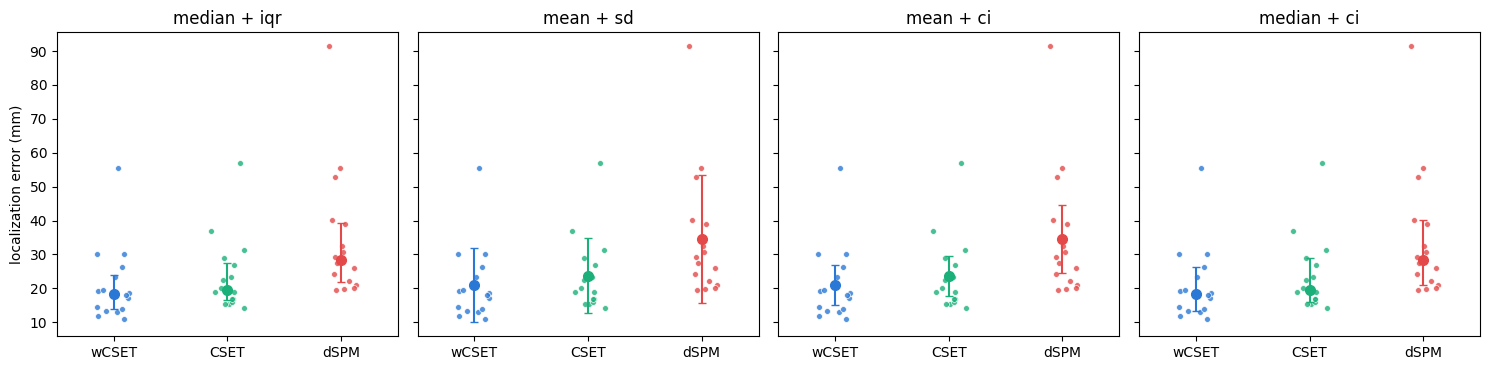

In [4]:
combos = [("median", "iqr"), ("mean", "sd"), ("mean", "ci"), ("median", "ci")]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), sharey=True)
for ax, (center, interval) in zip(axes, combos):
    suite.plot.point("loc_error_mm", x="method", unit="patient", order=ORDER, palette=COLORS,
                     center=center, interval=interval, points=True, ax=ax, xlabel="", ylabel="",
                     title=f"{center} + {interval}")
axes[0].set_ylabel("localization error (mm)")
fig.tight_layout()

Which to choose?

- Your test is a **Wilcoxon / Mann-Whitney** (rank-based) -> show **medians**.
- Your test is a **t-test** -> show **means**.
- Want to show **how patients vary** -> `iqr` or `sd`; want to show **how sure you
  are** about the center -> `ci`.

The stat plots make this choice for you (`center="auto"` picks the summary that
matches the test -- tutorial 3).

The numbers drawn are in the returned `Plot`, and the CI is exactly the one
`suite.estimate` reports -- the plot never computes its own statistics:

In [5]:
p = suite.plot.point("loc_error_mm", x="method", unit="patient", order=ORDER,
                     center="median", interval="ci")
plt.close(p.fig)
p.data[["method", "n", "center", "low", "high"]]

,method,n,center,low,high
0,wCSET,16,18.294337,13.427574,26.244171
1,CSET,16,19.541213,16.085498,28.908966
2,dSPM,16,28.361451,21.008694,40.151757


In [6]:
suite.estimate.median("loc_error_mm", group_by="method", pairing_col="patient").table

,group,estimate,ci_low,ci_high,n,ci_method
0,CSET,19.541213,16.085498,28.908966,16,binomial_exact
1,dSPM,28.361451,21.008694,40.151757,16,binomial_exact
2,wCSET,18.294337,13.427574,26.244171,16,binomial_exact


A box already shows median and IQR. Its `center`/`interval` arguments overlay a
marker on top -- e.g. the mean and its CI, to show how far the outlier drags the
mean:

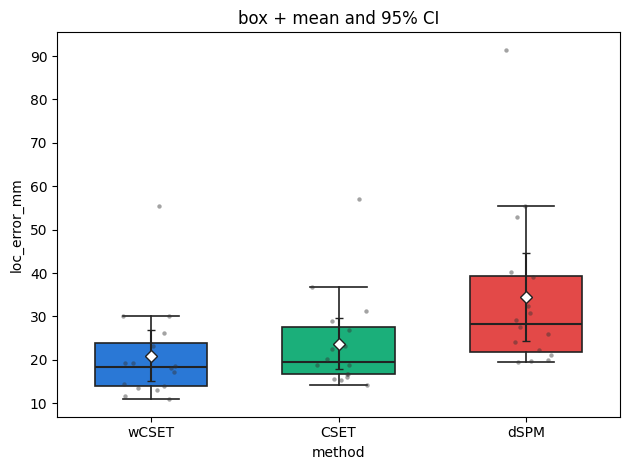

In [7]:
fig, ax = suite.plot.box("loc_error_mm", x="method", unit="patient", order=ORDER, palette=COLORS,
                         center="mean", interval="ci", title="box + mean and 95% CI")
fig.tight_layout()

## 🧩 - Part 3: Variables -- `x`, `hue` and `unit`

### `unit`: one point per patient

Each patient has 8 rows per method (2 SNR × 4 runs). Without `unit`, every row is a
point and the CI treats the 128 rows as independent patients -- it comes out far
too narrow. `unit="patient"` averages each patient's rows first: 16 points, an
honest interval.

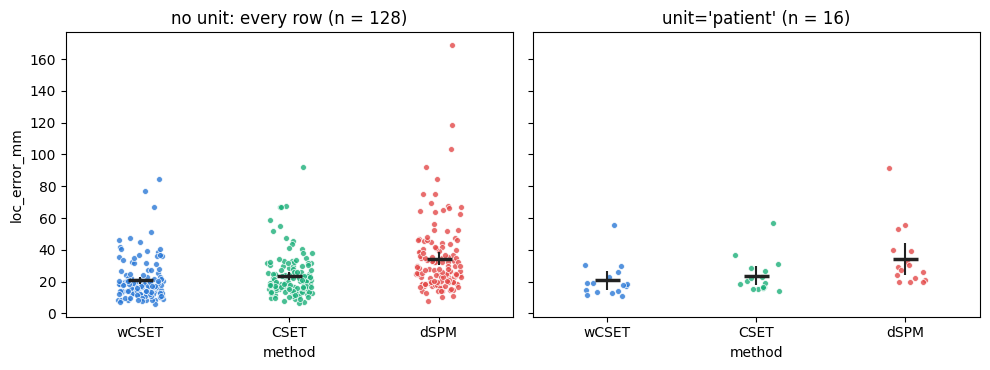

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
suite.plot.strip("loc_error_mm", x="method", order=ORDER, palette=COLORS, ax=axes[0],
                 title="no unit: every row (n = 128)")
suite.plot.strip("loc_error_mm", x="method", unit="patient", order=ORDER, palette=COLORS, ax=axes[1],
                 title="unit='patient' (n = 16)", ylabel="")
fig.tight_layout()

The difference in the numbers -- same means, very different intervals:

In [9]:
rows = suite.plot.point("loc_error_mm", x="method", order=ORDER)
units = suite.plot.point("loc_error_mm", x="method", unit="patient", order=ORDER)
plt.close("all")
rows.data[["method", "n", "low", "high"]].merge(
    units.data[["method", "n", "low", "high"]], on="method", suffixes=("_rows", "_patients"))

,method,n_rows,low_rows,high_rows,n_patients,low_patients,high_patients
0,wCSET,128,18.662730,23.231902,16,15.072586,26.822045
1,CSET,128,21.371186,26.043113,16,17.843937,29.570362
2,dSPM,128,30.531288,38.416712,16,24.426858,44.521142


### `hue`: a second grouping

`hue` splits each `x` level into side-by-side groups, colored by the hue level.
`filters` keeps only some rows. Here: both noise levels, then only the low-SNR
condition.

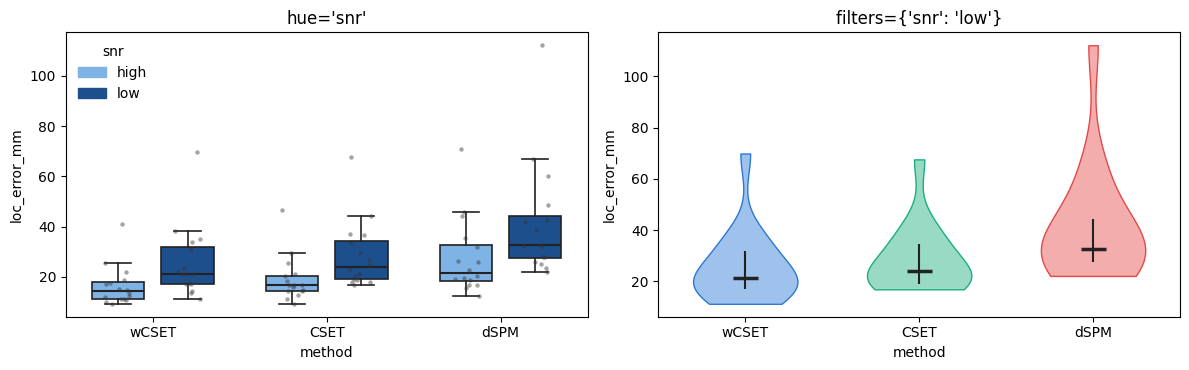

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
suite.plot.box("loc_error_mm", x="method", hue="snr", unit="patient", order=ORDER,
               hue_order=["high", "low"], palette={"high": "#7fb3e6", "low": "#1d4f8c"}, ax=axes[0],
               title="hue='snr'")
suite.plot.violin("loc_error_mm", x="method", unit="patient", order=ORDER, palette=COLORS,
                  filters={"snr": "low"}, ax=axes[1], title="filters={'snr': 'low'}")
fig.tight_layout()

## 📈 - Part 4: Distributions, curves, scatter plots

### Distributions

`distribution` draws a smoothed density (KDE) per `hue` level, `histogram` the raw
counts. Both take `unit` too. Useful to see skew, outliers and bimodality before
choosing a test.

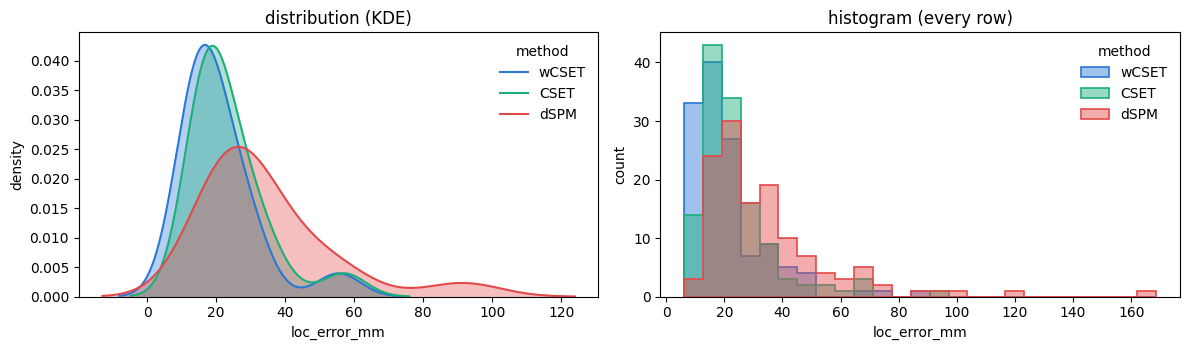

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
suite.plot.distribution("loc_error_mm", hue="method", unit="patient", hue_order=ORDER,
                        palette=COLORS, ax=axes[0], title="distribution (KDE)")
suite.plot.histogram("loc_error_mm", hue="method", hue_order=ORDER, palette=COLORS, ax=axes[1],
                     title="histogram (every row)", hist_kws={"bins": 25})
fig.tight_layout()

### Curves

`line` puts a numerical coordinate on the x-axis and draws `center` with its
`interval` at each point -- as a band (`interval_style="band"`, default) or error
bars. Here the mean correlation over time with a 95% CI across patients (each
patient's 4 runs averaged first).

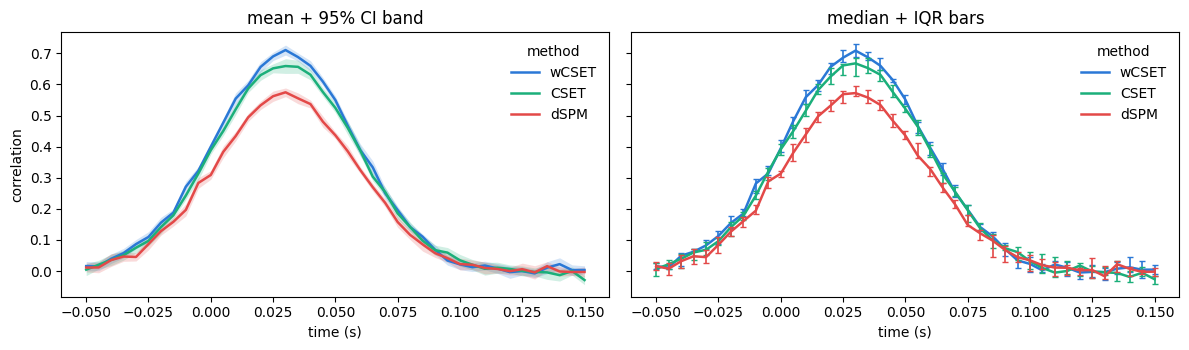

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
suite.plot.line("correlation_t", x="times", hue="method", unit="patient", hue_order=ORDER,
                palette=COLORS, ax=axes[0], title="mean + 95% CI band", xlabel="time (s)", ylabel="correlation")
suite.plot.line("correlation_t", x="times", hue="method", unit="patient", hue_order=ORDER,
                palette=COLORS, center="median", interval="iqr", interval_style="bars",
                ax=axes[1], title="median + IQR bars", xlabel="time (s)", ylabel="")
fig.tight_layout()

### Scatter plots

`scatter` plots the metric against a numerical label -- here, is the error larger
for deeper sources? `unit="patient"` gives one point per patient and method.

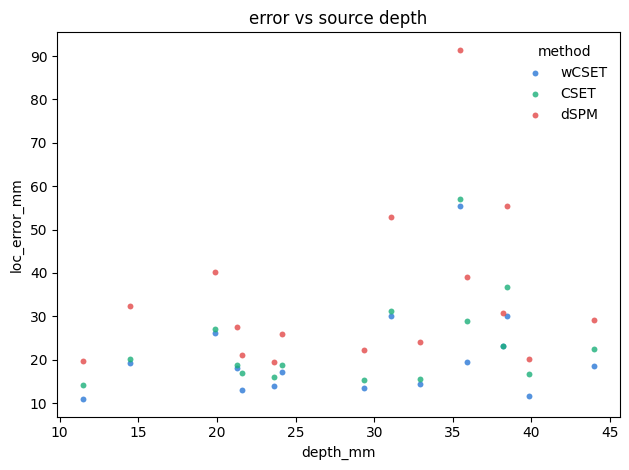

In [13]:
fig, ax = suite.plot.scatter("loc_error_mm", x="depth_mm", hue="method", unit="patient",
                             hue_order=ORDER, palette=COLORS, title="error vs source depth")
fig.tight_layout()

## 🎨 - Part 5: Styling and multi-panel figures

Every view takes the same styling arguments, so a style written once works
everywhere:

- **text**: `labels={level: "display name"}` (ticks and legend), `xlabel`, `ylabel`,
  `title` (`""` for none), `legend` (None = automatic, `True`, `False`,
  `"outside"`);
- **colors**: `palette` -- a `{level: color}` dict, a list, a colormap name, or None
  for the active matplotlib style; `fill_alpha` for the opacity of fills;
- **fine styling**: one `*_kws` dict per layer, passed to exactly one matplotlib
  call (`box_kws` -> `ax.bxp`, `points_kws` -> `ax.scatter`, `center_kws`,
  `interval_kws`, ...).

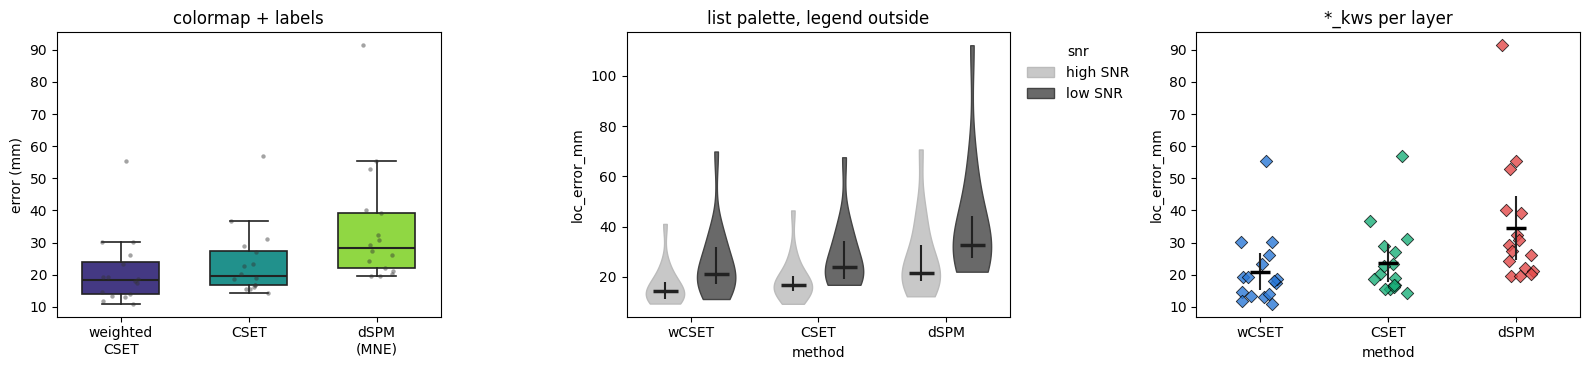

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
suite.plot.box(
    "loc_error_mm", x="method", unit="patient", order=ORDER, palette="viridis", ax=axes[0],
    labels={"wCSET": "weighted\nCSET", "dSPM": "dSPM\n(MNE)"}, title="colormap + labels",
    ylabel="error (mm)", xlabel="",
)
suite.plot.violin(
    "loc_error_mm", x="method", hue="snr", unit="patient", order=ORDER, hue_order=["high", "low"],
    palette=["#bbbbbb", "#444444"], fill_alpha=0.8, legend="outside", ax=axes[1],
    labels={"high": "high SNR", "low": "low SNR"}, title="list palette, legend outside",
)
suite.plot.strip(
    "loc_error_mm", x="method", unit="patient", order=ORDER, palette=COLORS, ax=axes[2],
    points_kws={"s": 40, "marker": "D", "edgecolor": "black"},
    center_kws={"markersize": 14, "color": "black"}, interval_kws={"linewidth": 3},
    title="*_kws per layer",
)
fig.tight_layout()

A matplotlib style changes every default at once -- with `palette=None`, the colors
come from the style's color cycle:

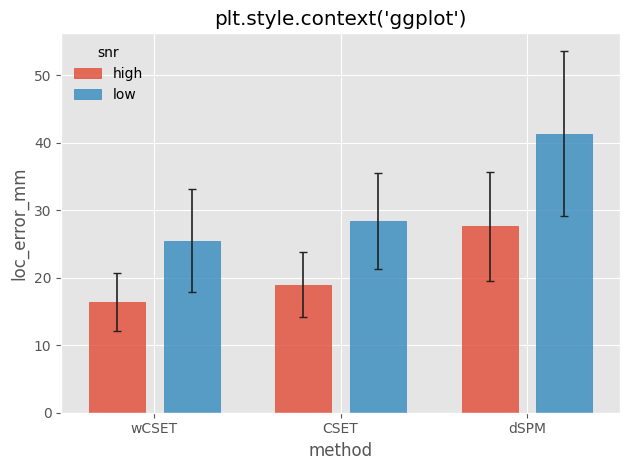

In [15]:
with plt.style.context("ggplot"):
    fig, ax = suite.plot.bar("loc_error_mm", x="method", hue="snr", unit="patient", order=ORDER,
                             title="plt.style.context('ggplot')")
    fig.tight_layout()

### After the fact: `Plot.artists`

The returned `Plot` keeps its matplotlib artists by layer, to restyle anything the
arguments don't cover:

['boxes', 'violins', 'bars', 'points', 'centers', 'intervals', 'box_parts']


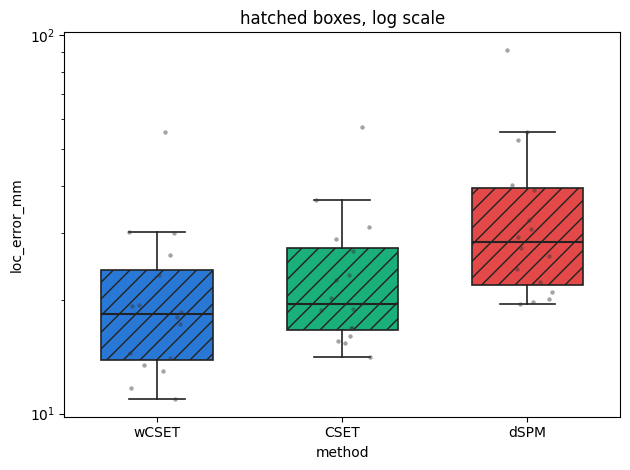

In [16]:
plot = suite.plot.box("loc_error_mm", x="method", unit="patient", order=ORDER, palette=COLORS)
print(list(plot.artists))
for box in plot.artists["boxes"]:
    box.set_hatch("//")
plot.ax.set_yscale("log")
plot.ax.set_title("hatched boxes, log scale")
plot.fig.tight_layout()

### Multi-panel figures

The suite never builds grids: you make the axes (`plt.subplots`, `GridSpec`,
`subfigures`...) and pass each one with `ax=`. A summary figure mixing views:

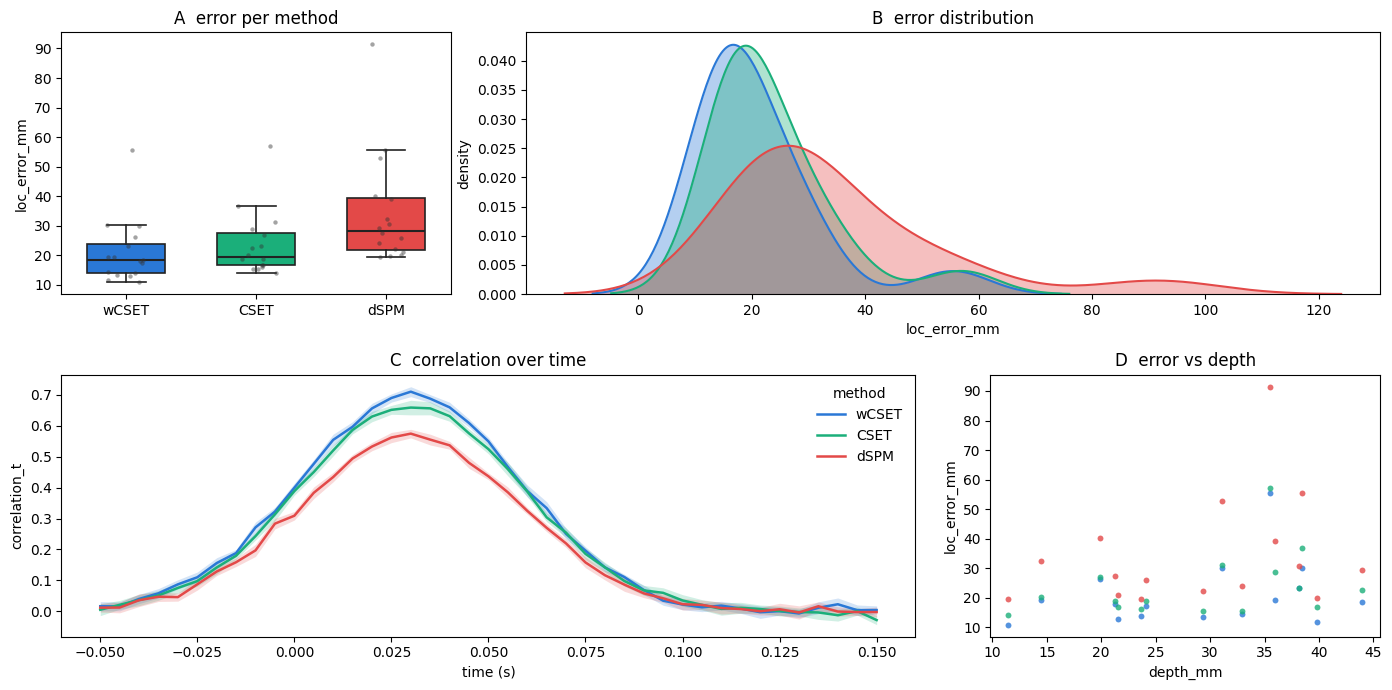

In [17]:
fig = plt.figure(figsize=(14, 7))
grid = fig.add_gridspec(2, 3)
ax_box = fig.add_subplot(grid[0, 0])
ax_kde = fig.add_subplot(grid[0, 1:])
ax_line = fig.add_subplot(grid[1, :2])
ax_scatter = fig.add_subplot(grid[1, 2])

suite.plot.box("loc_error_mm", x="method", unit="patient", order=ORDER, palette=COLORS, ax=ax_box,
               title="A  error per method", xlabel="")
suite.plot.distribution("loc_error_mm", hue="method", unit="patient", hue_order=ORDER,
                        palette=COLORS, ax=ax_kde, title="B  error distribution", legend=False)
suite.plot.line("correlation_t", x="times", hue="method", unit="patient", hue_order=ORDER,
                palette=COLORS, ax=ax_line, title="C  correlation over time", xlabel="time (s)")
suite.plot.scatter("loc_error_mm", x="depth_mm", hue="method", unit="patient", hue_order=ORDER,
                   palette=COLORS, ax=ax_scatter, title="D  error vs depth", legend=False)
fig.tight_layout()

## Wrap-up

- Data plots take a **metric name** and run no test: `box`, `violin`, `bar`,
  `point`, `strip` (groups), `distribution`, `histogram` (shape), `line` (curves),
  `scatter` (relations).
- `center` + `interval` choose the summary: **median + IQR / mean + SD for spread,
  a CI for precision**. Match it to your test.
- Always set `unit` to your independent unit (here the patient), or intervals
  treat repeated rows as independent.
- One set of styling arguments everywhere; `ax=` for your own layouts; the returned
  `Plot` keeps the numbers (`.data`) and the artists (`.artists`).

Next: **tutorial 3** chooses and runs the tests.